# Day 4 Practical – Clustering and PCA

**Accenture Bootcamp | Completed practical notebook**

This notebook completes Tasks 1–20 from `Day4_practice.ipynb` using the supplied `shopping-data.csv` and `penguins.csv` files.



## Setup and imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    silhouette_score, accuracy_score, classification_report,
    confusion_matrix, adjusted_rand_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Clustering tasks – Customer segmentation

### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv("shopping-data.csv")
display(customer_data.head())
print("Dataset shape:", customer_data.shape)
display(customer_data.describe(include="all"))

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


### 2. Scatter plot: annual income vs spending score

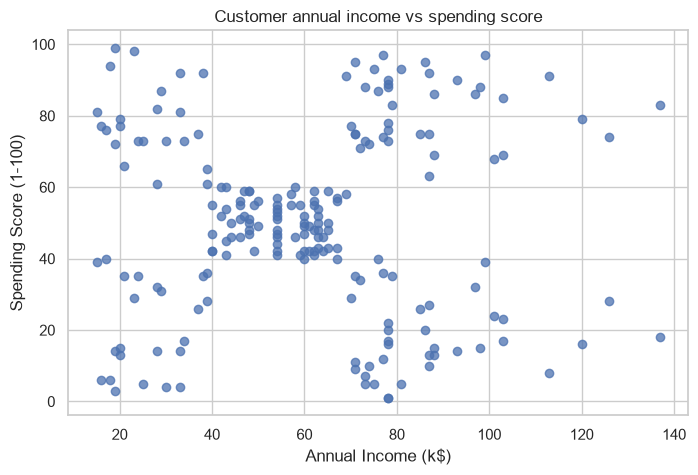

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(customer_data["Annual Income (k$)"],
            customer_data["Spending Score (1-100)"], alpha=0.75)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer annual income vs spending score")
plt.show()

### 3. Normalize the data

In [4]:
# These two numerical features are used for customer segmentation.
customer_features = customer_data[["Annual Income (k$)", "Spending Score (1-100)"]]
customer_scaler = StandardScaler()
X_customer_scaled = customer_scaler.fit_transform(customer_features)

print("Scaled data shape:", X_customer_scaled.shape)
print("Scaled feature means (approximately zero):", X_customer_scaled.mean(axis=0).round(3))

Scaled data shape: (200, 2)
Scaled feature means (approximately zero): [-0. -0.]


### 4. Elbow method to decide the number of clusters

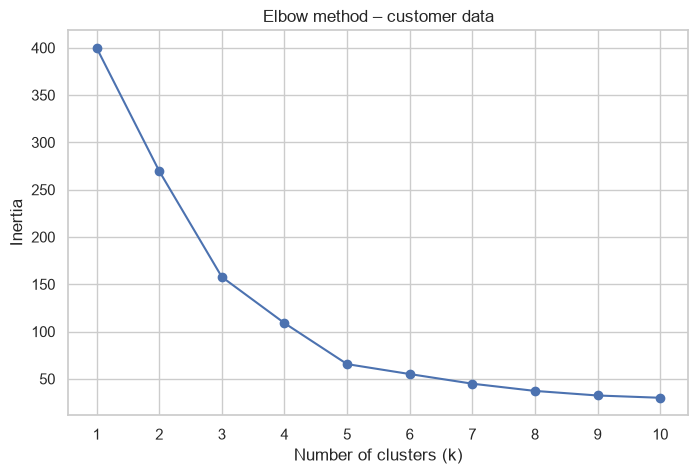

In [5]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_customer_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method – customer data")
plt.xticks(list(k_values))
plt.show()

**Interpretation:** The elbow is the point after which adding more clusters produces a smaller reduction in inertia. For this dataset, five clusters are a commonly useful segmentation choice. The elbow plot should be considered together with business context rather than as an exact automatic answer.

### 5. Perform clustering using K-Means

In [6]:
customer_k = 5
kmeans_customer = KMeans(n_clusters=customer_k, random_state=RANDOM_STATE, n_init=10)
customer_data["KMeans_Cluster"] = kmeans_customer.fit_predict(X_customer_scaled)

print("Cluster counts:")
display(customer_data["KMeans_Cluster"].value_counts().sort_index())
print("Silhouette score:", round(
    silhouette_score(X_customer_scaled, customer_data["KMeans_Cluster"]), 3
))

Cluster counts:


KMeans_Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Silhouette score: 0.555


### 6. Plot the customer clusters

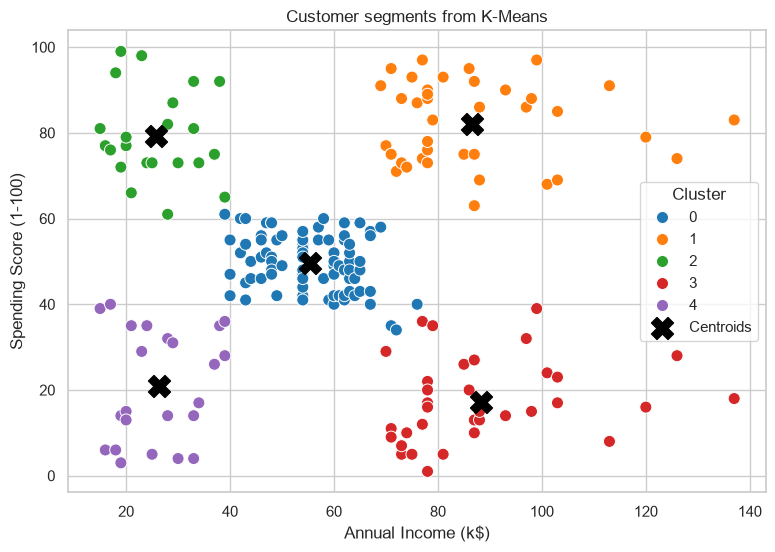

In [7]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=customer_data,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=75
)
centers_original_scale = customer_scaler.inverse_transform(kmeans_customer.cluster_centers_)
plt.scatter(centers_original_scale[:, 0], centers_original_scale[:, 1],
            marker="X", s=250, c="black", label="Centroids")
plt.title("Customer segments from K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

### 7. Dendrogram for Hierarchical Clustering

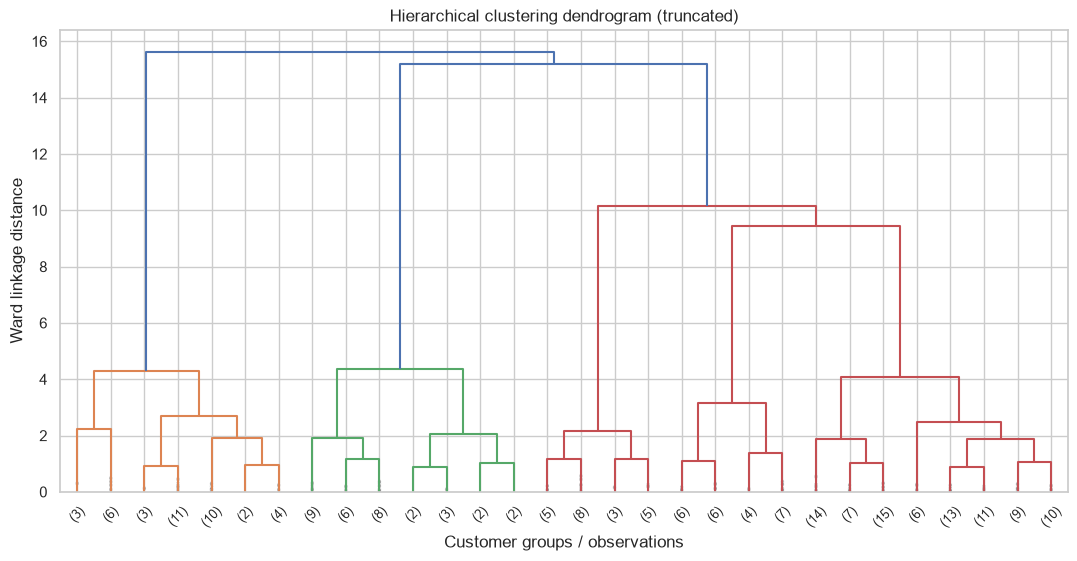

In [8]:
plt.figure(figsize=(13, 6))
linkage_matrix = linkage(X_customer_scaled, method="ward")
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=45,
           leaf_font_size=9, show_contracted=True)
plt.title("Hierarchical clustering dendrogram (truncated)")
plt.xlabel("Customer groups / observations")
plt.ylabel("Ward linkage distance")
plt.show()

**Explanation:** A possible cut is made across the dendrogram at a height before the large vertical merge distances. A cut around the major gap can suggest approximately **five clusters** for this customer dataset. The dendrogram is a visual guide; the selected number should also be checked against the scatter plot and the intended segmentation.

### 8. Perform Hierarchical Clustering

In [9]:
hierarchical_customer = AgglomerativeClustering(n_clusters=5, linkage="ward")
customer_data["Hierarchical_Cluster"] = hierarchical_customer.fit_predict(X_customer_scaled)

print("Hierarchical cluster counts:")
display(customer_data["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical cluster counts:


Hierarchical_Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

### 9. Plot the Hierarchical clusters

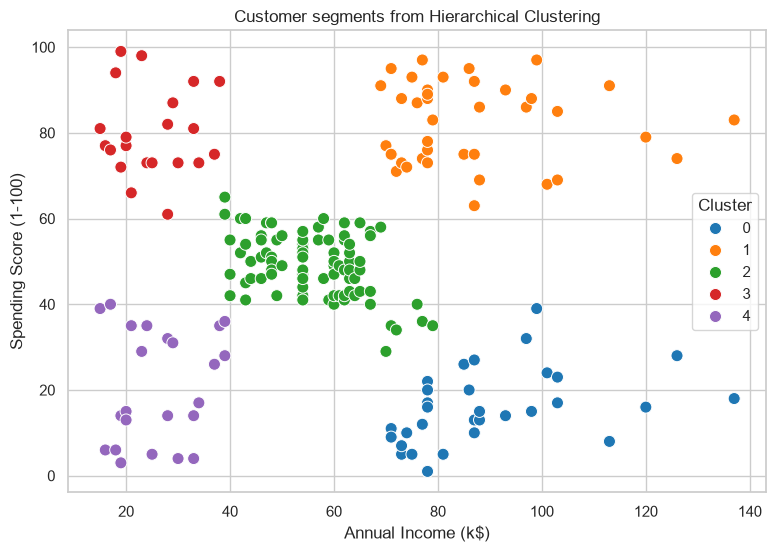

In [10]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=customer_data,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Hierarchical_Cluster",
    palette="tab10",
    s=75
)
plt.title("Customer segments from Hierarchical Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

### 10. K-Means and DBSCAN on the half-moons dataset

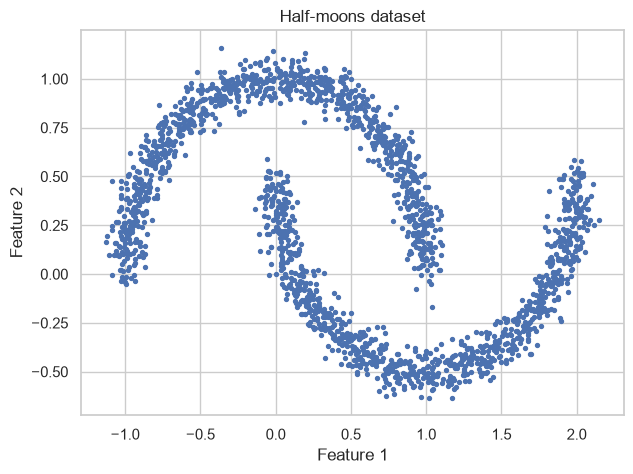

In [11]:
moons_X, moon_y = make_moons(n_samples=2000, noise=0.06, random_state=RANDOM_STATE)

plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], s=8)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Half-moons dataset")
plt.show()

#### K-Means clustering and plot

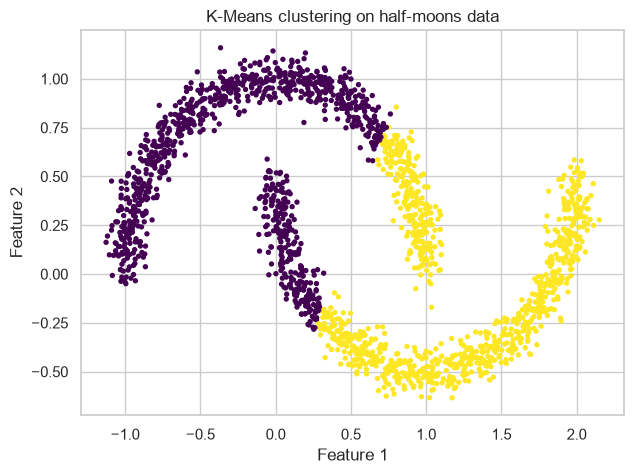

K-Means adjusted Rand index: 0.25


In [12]:
kmeans_moons = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
kmeans_moons_labels = kmeans_moons.fit_predict(moons_X)

plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=kmeans_moons_labels, cmap="viridis", s=8)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means clustering on half-moons data")
plt.show()

print("K-Means adjusted Rand index:", round(adjusted_rand_score(moon_y, kmeans_moons_labels), 3))

### 11. DBSCAN clustering, selecting eps and min_samples

Labels (-1 represents noise): [-1  0  1]
Number of clusters (excluding noise): 2
Number of noise points: 2


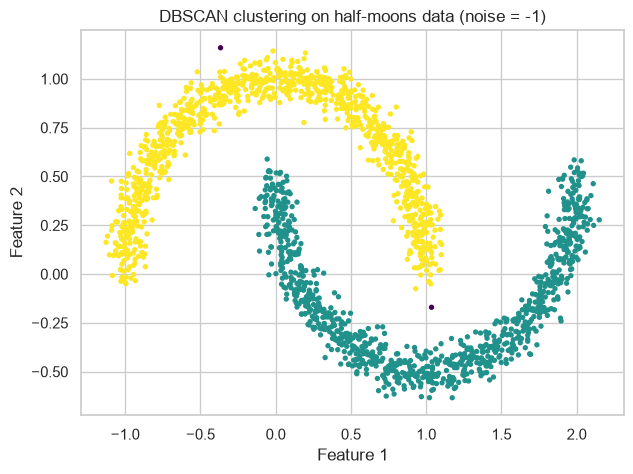

DBSCAN adjusted Rand index: 0.998


In [13]:
# Standardize the coordinates so eps has a meaningful scale.
moon_scaler = StandardScaler()
moons_scaled = moon_scaler.fit_transform(moons_X)

# This parameter combination typically identifies the two curved moon shapes.
dbscan_moons = DBSCAN(eps=0.22, min_samples=5)
dbscan_moons_labels = dbscan_moons.fit_predict(moons_scaled)

unique_labels = np.unique(dbscan_moons_labels)
print("Labels (-1 represents noise):", unique_labels)
print("Number of clusters (excluding noise):", len(set(dbscan_moons_labels)) - (1 if -1 in dbscan_moons_labels else 0))
print("Number of noise points:", int(np.sum(dbscan_moons_labels == -1)))

plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=dbscan_moons_labels, cmap="viridis", s=8)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN clustering on half-moons data (noise = -1)")
plt.show()

print("DBSCAN adjusted Rand index:", round(adjusted_rand_score(moon_y, dbscan_moons_labels), 3))

### 12. Compare K-Means and DBSCAN

**Comparison:** K-Means divides observations into a predefined number of compact groups around centroids. It works well for roughly spherical clusters, but it cannot naturally follow the curved, non-convex shapes in the half-moons dataset. DBSCAN groups points by density, can discover arbitrarily shaped clusters, and can label isolated observations as noise (`-1`). Therefore, **DBSCAN is generally preferable for the half-moons dataset**. Its result depends on `eps` and `min_samples`, so these values may need adjustment if the noise level or dataset changes.

# PCA tasks – Penguin dataset

### 13. Describe and explore the data

In [14]:
penguins = pd.read_csv("penguins.csv")
display(penguins.head())
print("Dataset shape:", penguins.shape)
print("\nData types and non-null counts:")
penguins.info()
print("\nNumerical summary:")
display(penguins.describe())
print("\nSex values:")
display(penguins["sex"].value_counts(dropna=False))

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


Dataset shape: (344, 5)

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB

Numerical summary:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000



Sex values:


sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

**Initial observations:** The dataset contains 344 rows and four numerical body measurements plus a `sex` column. There are missing numerical measurements and missing/invalid sex labels. The sex column contains the expected `MALE` and `FEMALE` values, missing values, and a `.` placeholder that should be treated as an unknown label rather than a valid class.

### 14. Explore corrupted data

In [15]:
print("Missing values per column:")
display(penguins.isna().sum())

missing_rows = penguins[penguins.isna().any(axis=1)]
print("Rows containing at least one missing value:", missing_rows.shape)
display(missing_rows)

print("All sex values, including missing:")
display(penguins["sex"].value_counts(dropna=False))

invalid_sex_rows = penguins[
    penguins["sex"].notna() & ~penguins["sex"].isin(["MALE", "FEMALE"])
]
print("Rows with unexpected sex labels:")
display(invalid_sex_rows)

Missing values per column:


culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

Rows containing at least one missing value: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


All sex values, including missing:


sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

Rows with unexpected sex labels:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,44.5,15.7,217.0,4875.0,.


**What is abnormal?** Some rows have missing measurements, some have a missing sex value, and one row uses `.` instead of `MALE` or `FEMALE`. The placeholder is not a valid class label. Rows with all measurements missing cannot be used to train a model or predict sex from body measurements.

### 15. Prepare valid data for PCA

In [16]:
numeric_features = [
    "culmen_length_mm", "culmen_depth_mm",
    "flipper_length_mm", "body_mass_g"
]
penguins_clean = penguins.copy()
penguins_clean["sex"] = penguins_clean["sex"].replace(".", np.nan)

# Keep only rows with all four measurements and a valid target class.
valid_mask = (
    penguins_clean[numeric_features].notna().all(axis=1)
    & penguins_clean["sex"].isin(["MALE", "FEMALE"])
)
penguins_valid = penguins_clean.loc[valid_mask].copy()

print("Original shape:", penguins.shape)
print("Clean labelled shape:", penguins_valid.shape)
display(penguins_valid.head())

Original shape: (344, 5)
Clean labelled shape: (334, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [17]:
# Fit scaler on the valid labelled training dataset.
penguin_scaler = StandardScaler()
X_penguins = penguin_scaler.fit_transform(penguins_valid[numeric_features])
y_penguins = penguins_valid["sex"].copy()

print("X_penguins shape:", X_penguins.shape)
print("y_penguins shape:", y_penguins.shape)
print("Target classes:", sorted(y_penguins.unique()))

X_penguins shape: (334, 4)
y_penguins shape: (334,)
Target classes: ['FEMALE', 'MALE']


**Null-value strategy:** Rows missing one or more numerical measurements are excluded because PCA and the classifier require complete numeric feature vectors. Rows with missing or invalid sex labels are excluded from supervised training because their correct target is unknown. This keeps the training data reliable and avoids inventing labels. The disadvantage is that fewer observations remain, which may reduce the amount of training information. Unknown-sex rows with complete measurements are kept separately for later prediction.

### 16. PCA with two components and plot

Shape after PCA: (334, 2)
Explained variance ratio: [0.46894303 0.25346954]
Total variance explained: 72.24%


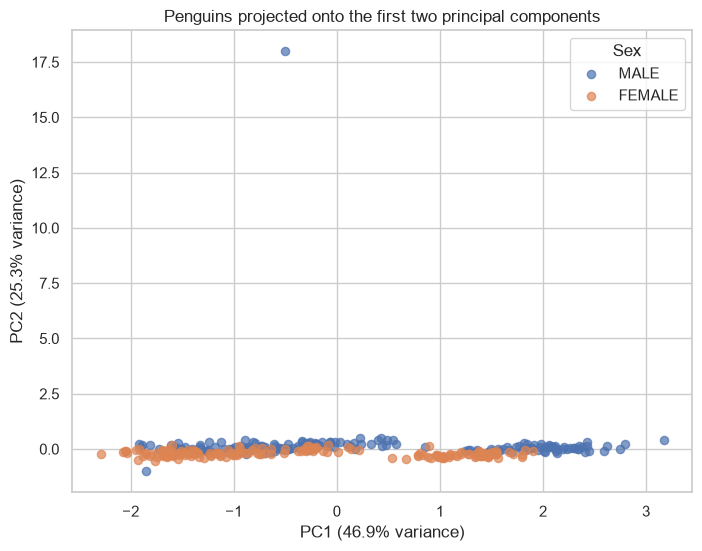

In [18]:
pca_penguins = PCA(n_components=2, random_state=RANDOM_STATE)
X_penguins_pca = pca_penguins.fit_transform(X_penguins)

print("Shape after PCA:", X_penguins_pca.shape)
print("Explained variance ratio:", pca_penguins.explained_variance_ratio_)
print("Total variance explained:", f"{pca_penguins.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(8, 6))
for sex in ["MALE", "FEMALE"]:
    mask = (y_penguins.to_numpy() == sex)
    plt.scatter(X_penguins_pca[mask, 0], X_penguins_pca[mask, 1],
                label=sex, alpha=0.7, s=35)
plt.xlabel(f"PC1 ({pca_penguins.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_penguins.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Penguins projected onto the first two principal components")
plt.legend(title="Sex")
plt.show()

### 17. Scree plot and cumulative explained variance

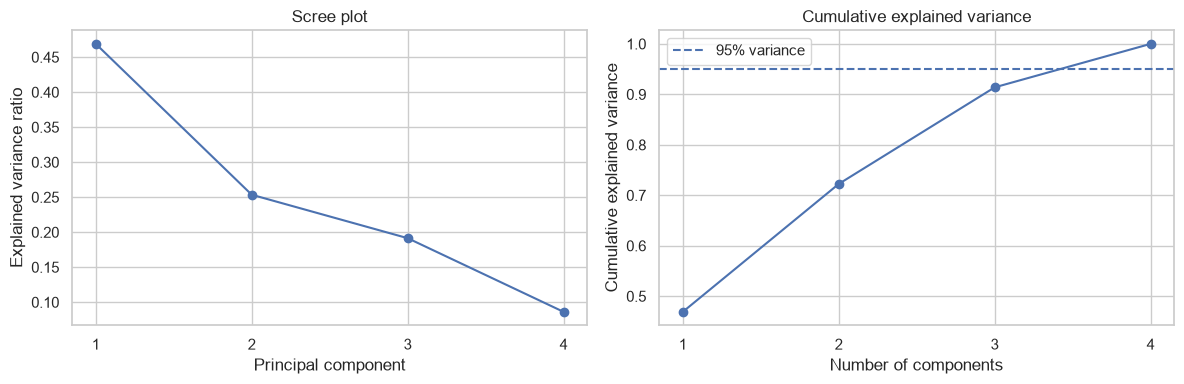

Explained variance by component:
PC1: 46.89%
PC2: 25.35%
PC3: 19.14%
PC4: 8.62%
Cumulative explained variance: [0.4689 0.7224 0.9138 1.    ]


In [19]:
pca_full_penguins = PCA()
pca_full_penguins.fit(X_penguins)

explained = pca_full_penguins.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(explained) + 1), explained, marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Scree plot")
axes[0].set_xticks(range(1, len(explained) + 1))

axes[1].plot(range(1, len(cumulative) + 1), cumulative, marker="o")
axes[1].axhline(0.95, linestyle="--", label="95% variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xticks(range(1, len(cumulative) + 1))
axes[1].legend()
plt.tight_layout()
plt.show()

print("Explained variance by component:")
for i, value in enumerate(explained, start=1):
    print(f"PC{i}: {value:.2%}")
print("Cumulative explained variance:", np.round(cumulative, 4))

**Interpretation:** The scree plot shows how much variance each component explains individually. The cumulative plot shows how much variance is retained when components are combined. Choose the smallest number of components that retains an acceptable proportion of variance for the intended task; two components are used above for visualization.

### 18. Calculate and display component loadings

In [20]:
loadings = pd.DataFrame(
    pca_penguins.components_.T,
    index=numeric_features,
    columns=["PC1", "PC2"]
)
print("PCA component loadings:")
display(loadings)

PCA component loadings:


,PC1,PC2
culmen_length_mm,0.570241,0.085418
culmen_depth_mm,-0.498432,0.205828
flipper_length_mm,0.023794,0.973716
body_mass_g,0.652552,0.047068


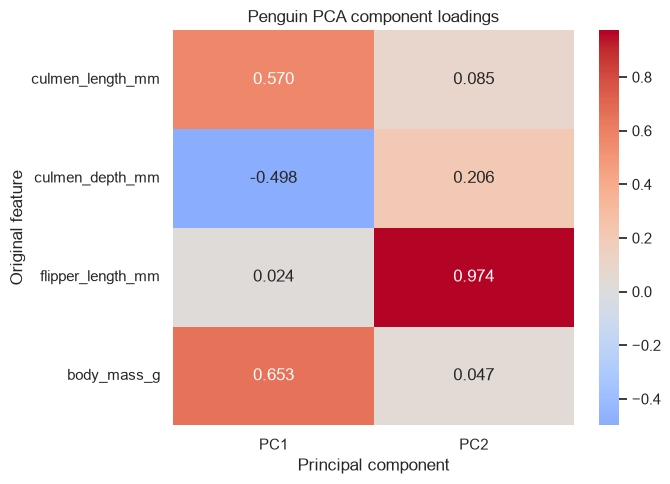

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("Penguin PCA component loadings")
plt.xlabel("Principal component")
plt.ylabel("Original feature")
plt.tight_layout()
plt.show()

**Interpretation:** A loading indicates how strongly an original measurement contributes to a principal component. Larger absolute values indicate a stronger contribution; the sign indicates the direction. The loadings are relative to the standardized features used for PCA.

### 19. Logistic regression using PCA-transformed data

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_penguins
)

penguin_classifier = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
penguin_classifier.fit(X_train, y_train)
y_pred = penguin_classifier.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred))
print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=["FEMALE", "MALE"]),
    index=["Actual FEMALE", "Actual MALE"],
    columns=["Predicted FEMALE", "Predicted MALE"]
))

Accuracy: 0.8452

Classification report:
              precision    recall  f1-score   support

      FEMALE       0.87      0.80      0.84        41
        MALE       0.83      0.88      0.85        43

    accuracy                           0.85        84
   macro avg       0.85      0.84      0.84        84
weighted avg       0.85      0.85      0.84        84

Confusion matrix:


,Predicted FEMALE,Predicted MALE
Actual FEMALE,33,8
Actual MALE,5,38


**Evaluation:** Accuracy is the proportion of test examples classified correctly. Precision, recall and F1-score in the classification report provide class-level detail. The test set was held out from model fitting, so it provides an estimate of performance on unseen labelled penguins.

### 20. Train on all valid labelled data and predict unknown sex values

In [23]:
# Unknown sex includes missing values and the '.' placeholder.
unknown_sex_mask = penguins_clean["sex"].isna()
unknown_with_features = unknown_sex_mask & penguins_clean[numeric_features].notna().all(axis=1)
penguins_to_predict = penguins_clean.loc[unknown_with_features].copy()

print("Unknown-sex rows in source data:", int(unknown_sex_mask.sum()))
print("Unknown-sex rows with all required measurements:", len(penguins_to_predict))
print("Rows excluded because measurements are incomplete:",
      int((unknown_sex_mask & ~penguins_clean[numeric_features].notna().all(axis=1)).sum()))
display(penguins_to_predict)

Unknown-sex rows in source data: 10
Unknown-sex rows with all required measurements: 8
Rows excluded because measurements are incomplete: 2


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,NaN


In [24]:
# Apply the same fitted scaler and PCA transformation to the unknown-sex rows.
X_unknown_scaled = penguin_scaler.transform(penguins_to_predict[numeric_features])
X_unknown_pca = pca_penguins.transform(X_unknown_scaled)

# Train a final classifier on all valid labelled observations.
final_penguin_classifier = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
final_penguin_classifier.fit(X_penguins_pca, y_penguins)

unknown_predictions = final_penguin_classifier.predict(X_unknown_pca)
prediction_results = penguins_to_predict[numeric_features].copy()
prediction_results["Predicted sex"] = unknown_predictions
display(prediction_results)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,Predicted sex
8,34.1,18.1,193.0,3475.0,FEMALE
10,37.8,17.1,186.0,3300.0,FEMALE
11,37.8,17.3,180.0,3700.0,FEMALE
47,37.5,18.9,179.0,2975.0,FEMALE
246,44.5,14.3,216.0,4100.0,FEMALE
286,46.2,14.4,214.0,4650.0,FEMALE
324,47.3,13.8,216.0,4725.0,FEMALE
336,44.5,15.7,217.0,4875.0,MALE


**Prediction note:** The model predicts sex only for rows where all four numerical measurements are available. The supplied file contains unknown-sex rows with missing measurements; those rows cannot be predicted from this feature set and are excluded rather than having measurements fabricated. Predictions are model estimates, not confirmed labels.

# Final summary

- Customer segmentation was performed with K-Means and Hierarchical Clustering using standardized annual income and spending score.
- On the non-convex half-moons data, DBSCAN can identify curved density-based groups more naturally than K-Means.
- Penguin data was inspected and cleaned before scaling and PCA.
- PCA reduced the four standardized measurements to two dimensions for visualization; explained variance and component loadings were examined.
- Logistic Regression was evaluated on a held-out test set and then refitted on all valid labelled observations to estimate the sex of eligible unknown-label rows.